# Home Credit Default Risk: Advanced Machine Learning Solution
A 5-fold stratified ensemble combining LightGBM, XGBoost, and CatBoost with out-of-fold target encoding, peer group aggregations, and rank blending.

Student: Andrés Ruz Teran.


In [4]:
# Install required specialized packages when running in Google Colab
import subprocess
import sys

for package in ["catboost", "optuna"]:
    try:
        __import__(package)
    except ImportError:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", package])


## 1. System Setup and Environment Configuration


In [5]:
import os
import gc
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score
from sklearn.preprocessing import OrdinalEncoder
from scipy.stats import rankdata
from scipy.optimize import minimize

import lightgbm as lgb
import xgboost as xgb
from catboost import CatBoostClassifier

# Global configuration constants
RANDOM_STATE = 42
N_SPLITS = 5

np.random.seed(RANDOM_STATE)


### 1.2 Google Drive Connection


In [6]:
# Mount Google Drive when running inside Google Colaboratory
try:
    from google.colab import drive
    drive.mount("/content/drive")
except Exception:
    pass

# Switch active directory to the repository workspace in Google Drive
for candidate in [
    Path("/content/drive/MyDrive/credit-default-risk-scoring"),
    Path("/content/drive/MyDrive/credit-default-risk-scoring/Competition"),
    Path("/content/drive/MyDrive/Competition"),
    Path("/content/drive/MyDrive/competition"),
    Path("/content/drive/MyDrive/GCI/credit-default-risk-scoring"),
    Path("/content/drive/MyDrive/GCI/Competition")
]:
    if candidate.exists():
        os.chdir(candidate)
        break

print("Active working directory:", Path.cwd())


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Active working directory: /content


## 2. Dynamic Data Ingestion and Validation


In [7]:
# Search candidate directory paths for input data
current_dir = Path.cwd()

candidate_paths = [
    current_dir / "input",
    current_dir.parent / "input",
    Path("/content/drive/MyDrive/credit-default-risk-scoring/input"),
    Path("/content/drive/MyDrive/Competition/input"),
    Path("/content/drive/MyDrive/competition/input"),
    Path("/content/credit-default-risk-scoring/input"),
    Path("/content/competition/input"),
    Path("/content/input")
]

input_dir = None
for path in candidate_paths:
    if (path / "train.csv").exists():
        input_dir = path
        break

if input_dir is None and Path("/content/drive/MyDrive").exists():
    matches = list(Path("/content/drive/MyDrive").glob("**/input/train.csv"))
    if matches:
        input_dir = matches[0].parent

if input_dir is None:
    raise FileNotFoundError("Could not locate train.csv in candidate paths")

print("Identified input data directory:", input_dir)

# Load training and test datasets
train_df = pd.read_csv(input_dir / "train.csv")
test_df = pd.read_csv(input_dir / "test.csv")
sample_sub = pd.read_csv(input_dir / "sample_submission.csv")

print("Training partition dimensions:", train_df.shape)
print("Testing partition dimensions:", test_df.shape)
print("Default class distribution:")
print(train_df["TARGET"].value_counts(normalize=True))


Identified input data directory: /content/drive/MyDrive/Competition/input
Training partition dimensions: (171202, 34)
Testing partition dimensions: (61500, 33)
Default class distribution:
TARGET
0    0.919271
1    0.080729
Name: proportion, dtype: float64


## 3. Advanced Domain Feature Engineering
Feature pipeline incorporates:
1. Anomaly disentanglement on DAYS_EMPLOYED sentinel (365243) and missingness counters.
2. Debt solvency, payment term, and affordability ratios.
3. Chronometric age and employment duration differences.
4. Polynomial and interaction terms for external bureau scores (EXT_SOURCE_1, 2, 3).
5. Peer group mean aggregations by organization, occupation, and education.
6. Categorical frequency encoding.


In [8]:
def engineer_features(raw_train, raw_test):
    # Combine sets temporarily for consistent transformation
    df_all = pd.concat([raw_train.assign(is_train=1), raw_test.assign(is_train=0, TARGET=np.nan)], ignore_index=True)

    # Anomaly identification and sentinel replacement
    df_all["DAYS_EMPLOYED_ANOM"] = (df_all["DAYS_EMPLOYED"] == 365243).astype(int)
    df_all["DAYS_EMPLOYED"] = df_all["DAYS_EMPLOYED"].replace(365243, np.nan)
    df_all["CODE_GENDER"] = df_all["CODE_GENDER"].replace("XNA", "F")

    # Missing value volume indicators
    df_all["TOTAL_NULLS"] = df_all.isnull().sum(axis=1)
    df_all["EXT_NULLS"] = df_all[["EXT_SOURCE_1", "EXT_SOURCE_2", "EXT_SOURCE_3"]].isnull().sum(axis=1)

    # Financial solvency and capacity ratios
    df_all["CREDIT_INCOME_RATIO"] = df_all["AMT_CREDIT"] / (df_all["AMT_INCOME_TOTAL"] + 1e-5)
    df_all["ANNUITY_INCOME_RATIO"] = df_all["AMT_ANNUITY"] / (df_all["AMT_INCOME_TOTAL"] + 1e-5)
    df_all["PAYMENT_RATE"] = df_all["AMT_ANNUITY"] / (df_all["AMT_CREDIT"] + 1e-5)
    df_all["CREDIT_TERM"] = df_all["AMT_CREDIT"] / (df_all["AMT_ANNUITY"] + 1e-5)
    df_all["GOODS_CREDIT_RATIO"] = df_all["AMT_GOODS_PRICE"] / (df_all["AMT_CREDIT"] + 1e-5)
    df_all["CREDIT_GOODS_DIFF"] = df_all["AMT_CREDIT"] - df_all["AMT_GOODS_PRICE"]
    df_all["INCOME_PER_FAMILY_MEMBER"] = df_all["AMT_INCOME_TOTAL"] / (df_all["CNT_FAM_MEMBERS"].fillna(1))

    # Age and professional tenure chronometrics
    df_all["AGE_YEARS"] = -df_all["DAYS_BIRTH"] / 365.25
    df_all["EMPLOYED_YEARS"] = -df_all["DAYS_EMPLOYED"] / 365.25
    df_all["DAYS_EMPLOYED_PERCENT"] = df_all["DAYS_EMPLOYED"] / (df_all["DAYS_BIRTH"] + 1e-5)
    df_all["AGE_AT_EMPLOYMENT"] = df_all["DAYS_EMPLOYED"] - df_all["DAYS_BIRTH"]
    df_all["DAYS_ID_TO_BIRTH"] = df_all["DAYS_ID_PUBLISH"] - df_all["DAYS_BIRTH"]
    df_all["DAYS_REG_TO_BIRTH"] = df_all["DAYS_REGISTRATION"] - df_all["DAYS_BIRTH"]
    df_all["PHONE_TO_BIRTH_RATIO"] = df_all["DAYS_LAST_PHONE_CHANGE"] / (df_all["DAYS_BIRTH"] + 1e-5)
    df_all["PHONE_TO_EMPLOYED_RATIO"] = df_all["DAYS_LAST_PHONE_CHANGE"] / (df_all["DAYS_EMPLOYED"] + 1e-5)

    # External bureau scores composite statistics
    ext_cols = ["EXT_SOURCE_1", "EXT_SOURCE_2", "EXT_SOURCE_3"]
    df_all["EXT_SOURCES_MEAN"] = df_all[ext_cols].mean(axis=1)
    df_all["EXT_SOURCES_STD"] = df_all[ext_cols].std(axis=1).fillna(0)
    df_all["EXT_SOURCES_MIN"] = df_all[ext_cols].min(axis=1)
    df_all["EXT_SOURCES_MAX"] = df_all[ext_cols].max(axis=1)
    df_all["EXT_SOURCES_PROD"] = df_all["EXT_SOURCE_1"] * df_all["EXT_SOURCE_2"] * df_all["EXT_SOURCE_3"]
    df_all["EXT_2_x_3"] = df_all["EXT_SOURCE_2"] * df_all["EXT_SOURCE_3"]
    df_all["EXT_1_x_2"] = df_all["EXT_SOURCE_1"] * df_all["EXT_SOURCE_2"]
    df_all["EXT_1_x_3"] = df_all["EXT_SOURCE_1"] * df_all["EXT_SOURCE_3"]
    df_all["EXT_2_sq"] = df_all["EXT_SOURCE_2"] ** 2
    df_all["EXT_3_sq"] = df_all["EXT_SOURCE_3"] ** 2
    df_all["EXT_2_x_AGE"] = df_all["EXT_SOURCE_2"] * df_all["DAYS_BIRTH"]
    df_all["EXT_3_x_AGE"] = df_all["EXT_SOURCE_3"] * df_all["DAYS_BIRTH"]

    # Peer group statistics across categories
    for grp in ["ORGANIZATION_TYPE", "OCCUPATION_TYPE", "NAME_EDUCATION_TYPE"]:
        for col in ["AMT_INCOME_TOTAL", "AMT_CREDIT", "EXT_SOURCE_2", "EXT_SOURCE_3"]:
            grp_mean = df_all.groupby(grp)[col].transform("mean")
            df_all[f"{col}_TO_{grp}_MEAN"] = df_all[col] / (grp_mean + 1e-5)

    # Frequency encoding on categorical features
    for c in ["ORGANIZATION_TYPE", "OCCUPATION_TYPE", "NAME_INCOME_TYPE", "NAME_EDUCATION_TYPE"]:
        df_all[f"{c}_COUNT"] = df_all[c].map(df_all[c].value_counts())

    # Bureau inquiries and contactability aggregates
    df_all["BUREAU_REQ_TOTAL"] = (
        df_all["AMT_REQ_CREDIT_BUREAU_HOUR"].fillna(0) +
        df_all["AMT_REQ_CREDIT_BUREAU_MON"].fillna(0) +
        df_all["AMT_REQ_CREDIT_BUREAU_QRT"].fillna(0) +
        df_all["AMT_REQ_CREDIT_BUREAU_YEAR"].fillna(0)
    )
    df_all["FLAGS_PHONE_TOTAL"] = df_all["FLAG_MOBIL"] + df_all["FLAG_EMP_PHONE"] + df_all["FLAG_WORK_PHONE"]

    # Logarithmic scaling of heavy-tailed monetary amounts
    df_all["LOG_INCOME"] = np.log1p(df_all["AMT_INCOME_TOTAL"])
    df_all["LOG_CREDIT"] = np.log1p(df_all["AMT_CREDIT"])
    df_all["LOG_ANNUITY"] = np.log1p(df_all["AMT_ANNUITY"])

    tr_df = df_all[df_all["is_train"] == 1].drop(columns=["is_train"])
    te_df = df_all[df_all["is_train"] == 0].drop(columns=["is_train", "TARGET"])
    return tr_df, te_df

# Execute feature engineering
train_processed, test_processed = engineer_features(train_df, test_df)
print("Engineered feature matrix dimensions:", train_processed.shape)


Engineered feature matrix dimensions: (171202, 85)


## 4. Categorical Encoding and Data Matrix Preparation


In [9]:
# Categorical feature columns
categorical_features = [
    "NAME_CONTRACT_TYPE", "CODE_GENDER", "NAME_INCOME_TYPE", "NAME_EDUCATION_TYPE",
    "NAME_FAMILY_STATUS", "NAME_HOUSING_TYPE", "OCCUPATION_TYPE", "ORGANIZATION_TYPE"
]

# Preserve copy for target encoding within cross validation
train_cats_raw = train_processed[categorical_features].copy().astype(str)
test_cats_raw = test_processed[categorical_features].copy().astype(str)

# Apply ordinal encoding for general tree split support
encoder = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)
train_processed[categorical_features] = encoder.fit_transform(train_cats_raw)
test_processed[categorical_features] = encoder.transform(test_cats_raw)

# Separate predictors and target variable
feature_columns = [col for col in train_processed.columns if col not in ["SK_ID_CURR", "TARGET"]]

X = train_processed[feature_columns].copy()
y = train_processed["TARGET"].copy()
X_test = test_processed[feature_columns].copy()

print(f"Total base predictor variables: {X.shape[1]}")


Total base predictor variables: 83


## 5. Stratified Cross-Validation Strategy
A 5-fold stratified cross-validation setup enforces zero data leakage. Target encoding for high-cardinality nominal variables is computed strictly out of fold using smoothed Bayesian means.


In [10]:
# Initialize five stratified folds
cv = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_STATE)

# Allocate out of fold and test probability matrices
oof_lgb = np.zeros(len(train_processed))
oof_xgb = np.zeros(len(train_processed))
oof_cat = np.zeros(len(train_processed))

test_lgb = np.zeros(len(test_processed))
test_xgb = np.zeros(len(test_processed))
test_cat = np.zeros(len(test_processed))

# Dynamic feature importance accumulator
feature_importances_lgb = None
engineered_feature_names = None

def apply_target_encoding(X_tr, y_tr, X_va, X_te, cat_cols, smoothing=10):
    global_mean = y_tr.mean()
    X_tr_out = X_tr.copy()
    X_va_out = X_va.copy()
    X_te_out = X_te.copy()
    
    for c in cat_cols:
        stats = y_tr.groupby(X_tr[c]).agg(["count", "mean"])
        smoothed = (stats["count"] * stats["mean"] + smoothing * global_mean) / (stats["count"] + smoothing)
        X_tr_out[f"{c}_TE"] = X_tr[c].map(smoothed).fillna(global_mean)
        X_va_out[f"{c}_TE"] = X_va[c].map(smoothed).fillna(global_mean)
        X_te_out[f"{c}_TE"] = X_te[c].map(smoothed).fillna(global_mean)
        
    return X_tr_out, X_va_out, X_te_out


## 6. Model 1: LightGBM Classifier


In [11]:
# Hyperparameters for LightGBM
lgb_params = {
    "objective": "binary",
    "metric": "auc",
    "boosting_type": "gbdt",
    "learning_rate": 0.03,
    "num_leaves": 63,
    "max_depth": -1,
    "feature_fraction": 0.7,
    "bagging_fraction": 0.7,
    "bagging_freq": 1,
    "min_child_samples": 50,
    "lambda_l1": 2.0,
    "lambda_l2": 5.0,
    "random_state": RANDOM_STATE,
    "n_estimators": 2500,
    "verbose": -1,
    "n_jobs": -1
}

te_categories = ["ORGANIZATION_TYPE", "OCCUPATION_TYPE", "NAME_EDUCATION_TYPE", "NAME_INCOME_TYPE"]

# Cross validation loop for LightGBM
for fold, (train_idx, val_idx) in enumerate(cv.split(X, y)):
    X_train_fold, y_train_fold = X.iloc[train_idx].copy(), y.iloc[train_idx].copy()
    X_val_fold, y_val_fold = X.iloc[val_idx].copy(), y.iloc[val_idx].copy()
    X_test_fold = X_test.copy()
    
    # Compute leak free target encoding on training fold
    X_train_fold, X_val_fold, X_test_fold = apply_target_encoding(
        X_train_fold, y_train_fold, X_val_fold, X_test_fold, te_categories
    )
    
    if engineered_feature_names is None:
        engineered_feature_names = list(X_train_fold.columns)
        feature_importances_lgb = np.zeros(len(engineered_feature_names))
    
    model_lgb = lgb.LGBMClassifier(**lgb_params)
    model_lgb.fit(
        X_train_fold, y_train_fold,
        eval_set=[(X_val_fold, y_val_fold)],
        callbacks=[lgb.early_stopping(stopping_rounds=150, verbose=False)]
    )
    
    val_pred = model_lgb.predict_proba(X_val_fold)[:, 1]
    oof_lgb[val_idx] = val_pred
    test_lgb += model_lgb.predict_proba(X_test_fold)[:, 1] / N_SPLITS
    feature_importances_lgb += model_lgb.feature_importances_ / N_SPLITS
    
    fold_auc = roc_auc_score(y_val_fold, val_pred)
    print(f"LightGBM Fold {fold + 1} ROC-AUC: {fold_auc:.5f}")

overall_lgb_auc = roc_auc_score(y, oof_lgb)
print(f"Overall LightGBM OOF ROC-AUC: {overall_lgb_auc:.5f}")


LightGBM Fold 1 ROC-AUC: 0.75728
LightGBM Fold 2 ROC-AUC: 0.75952
LightGBM Fold 3 ROC-AUC: 0.76476
LightGBM Fold 4 ROC-AUC: 0.75473
LightGBM Fold 5 ROC-AUC: 0.76149
Overall LightGBM OOF ROC-AUC: 0.75952


## 7. Model 2: XGBoost Classifier


In [12]:
# Hyperparameters for XGBoost
xgb_params = {
    "n_estimators": 2000,
    "learning_rate": 0.03,
    "max_depth": 6,
    "subsample": 0.7,
    "colsample_bytree": 0.7,
    "reg_alpha": 2.0,
    "reg_lambda": 5.0,
    "tree_method": "hist",
    "eval_metric": "auc",
    "early_stopping_rounds": 150,
    "random_state": RANDOM_STATE,
    "n_jobs": -1
}

# Cross validation loop for XGBoost
for fold, (train_idx, val_idx) in enumerate(cv.split(X, y)):
    X_train_fold, y_train_fold = X.iloc[train_idx].copy(), y.iloc[train_idx].copy()
    X_val_fold, y_val_fold = X.iloc[val_idx].copy(), y.iloc[val_idx].copy()
    X_test_fold = X_test.copy()

    X_train_fold, X_val_fold, X_test_fold = apply_target_encoding(
        X_train_fold, y_train_fold, X_val_fold, X_test_fold, te_categories
    )

    model_xgb = xgb.XGBClassifier(**xgb_params)
    model_xgb.fit(
        X_train_fold, y_train_fold,
        eval_set=[(X_val_fold, y_val_fold)],
        verbose=False
    )

    val_pred = model_xgb.predict_proba(X_val_fold)[:, 1]
    oof_xgb[val_idx] = val_pred
    test_xgb += model_xgb.predict_proba(X_test_fold)[:, 1] / N_SPLITS

    fold_auc = roc_auc_score(y_val_fold, val_pred)
    print(f"XGBoost Fold {fold + 1} ROC-AUC: {fold_auc:.5f}")

overall_xgb_auc = roc_auc_score(y, oof_xgb)
print(f"Overall XGBoost OOF ROC-AUC: {overall_xgb_auc:.5f}")


XGBoost Fold 1 ROC-AUC: 0.75721
XGBoost Fold 2 ROC-AUC: 0.76081
XGBoost Fold 3 ROC-AUC: 0.76619
XGBoost Fold 4 ROC-AUC: 0.75481
XGBoost Fold 5 ROC-AUC: 0.76137
Overall XGBoost OOF ROC-AUC: 0.76004


## 8. Model 3: CatBoost Classifier


In [13]:
# Cross validation loop for CatBoost
for fold, (train_idx, val_idx) in enumerate(cv.split(X, y)):
    X_train_fold, y_train_fold = X.iloc[train_idx].copy(), y.iloc[train_idx].copy()
    X_val_fold, y_val_fold = X.iloc[val_idx].copy(), y.iloc[val_idx].copy()
    X_test_fold = X_test.copy()

    X_train_fold, X_val_fold, X_test_fold = apply_target_encoding(
        X_train_fold, y_train_fold, X_val_fold, X_test_fold, te_categories
    )

    model_cat = CatBoostClassifier(
        iterations=2000,
        learning_rate=0.03,
        depth=6,
        l2_leaf_reg=5.0,
        eval_metric="AUC",
        random_seed=RANDOM_STATE,
        early_stopping_rounds=150,
        allow_writing_files=False,
        verbose=False
    )
    model_cat.fit(
        X_train_fold, y_train_fold,
        eval_set=(X_val_fold, y_val_fold),
        verbose=False
    )

    val_pred = model_cat.predict_proba(X_val_fold)[:, 1]
    oof_cat[val_idx] = val_pred
    test_cat += model_cat.predict_proba(X_test_fold)[:, 1] / N_SPLITS

    fold_auc = roc_auc_score(y_val_fold, val_pred)
    print(f"CatBoost Fold {fold + 1} ROC-AUC: {fold_auc:.5f}")

overall_cat_auc = roc_auc_score(y, oof_cat)
print(f"Overall CatBoost OOF ROC-AUC: {overall_cat_auc:.5f}")


CatBoost Fold 1 ROC-AUC: 0.75709
CatBoost Fold 2 ROC-AUC: 0.76140
CatBoost Fold 3 ROC-AUC: 0.76473
CatBoost Fold 4 ROC-AUC: 0.75607
CatBoost Fold 5 ROC-AUC: 0.76088
Overall CatBoost OOF ROC-AUC: 0.76000


## 9. Rank-Based Ensemble Optimization
Predictions are converted to relative percentile rankings to align probability distributions. Blending weights are determined by solving a constrained non-linear optimization problem on out-of-fold rank predictions.


In [14]:
# Convert model out of fold predictions to percentile ranks
rank_oof_lgb = rankdata(oof_lgb) / len(oof_lgb)
rank_oof_xgb = rankdata(oof_xgb) / len(oof_xgb)
rank_oof_cat = rankdata(oof_cat) / len(oof_cat)

rank_test_lgb = rankdata(test_lgb) / len(test_lgb)
rank_test_xgb = rankdata(test_xgb) / len(test_xgb)
rank_test_cat = rankdata(test_cat) / len(test_cat)

# Objective function returning negative out of fold ROC-AUC
def rank_objective(weights):
    weights = weights / np.sum(weights)
    blended_rank = (
        weights[0] * rank_oof_lgb +
        weights[1] * rank_oof_xgb +
        weights[2] * rank_oof_cat
    )
    return -roc_auc_score(y, blended_rank)

# Constrained SLSQP optimization for ensemble weights
initial_weights = [1.0 / 3.0, 1.0 / 3.0, 1.0 / 3.0]
bounds = [(0.0, 1.0), (0.0, 1.0), (0.0, 1.0)]
constraints = {"type": "eq", "fun": lambda w: np.sum(w) - 1.0}

opt_res = minimize(rank_objective, initial_weights, method="SLSQP", bounds=bounds, constraints=constraints)
optimal_weights = opt_res.x / np.sum(opt_res.x)

# Optimal blended out of fold rank predictions
oof_rank_ensemble = (
    optimal_weights[0] * rank_oof_lgb +
    optimal_weights[1] * rank_oof_xgb +
    optimal_weights[2] * rank_oof_cat
)

ensemble_auc = roc_auc_score(y, oof_rank_ensemble)

print("Optimal Ensemble Weights:")
print(f"LightGBM: {optimal_weights[0]:.4f}")
print(f"XGBoost:  {optimal_weights[1]:.4f}")
print(f"CatBoost: {optimal_weights[2]:.4f}")
print(f"Final Ensemble Out-Of-Fold ROC-AUC: {ensemble_auc:.5f}")


Optimal Ensemble Weights:
LightGBM: 0.3330
XGBoost:  0.3336
CatBoost: 0.3334
Final Ensemble Out-Of-Fold ROC-AUC: 0.76170


## 10. Performance Audit and Comparative Analysis


In [15]:
# Construct performance comparison table
results_summary = pd.DataFrame({
    "Model Configuration": [
        "Course Tutorial Baseline (Random Forest)",
        "LightGBM (5-Fold CV + Advanced FE)",
        "XGBoost (5-Fold CV + Advanced FE)",
        "CatBoost (5-Fold CV + Advanced FE)",
        "Ensemble Solution (SLSQP Rank Blend)"
    ],
    "Validation ROC-AUC": [
        0.73245,
        overall_lgb_auc,
        overall_xgb_auc,
        overall_cat_auc,
        ensemble_auc
    ],
    "AUC Gain Over Baseline": [
        0.00000,
        overall_lgb_auc - 0.73245,
        overall_xgb_auc - 0.73245,
        overall_cat_auc - 0.73245,
        ensemble_auc - 0.73245
    ]
})

print(results_summary.to_string(index=False))


                     Model Configuration  Validation ROC-AUC  AUC Gain Over Baseline
Course Tutorial Baseline (Random Forest)            0.732450                0.000000
      LightGBM (5-Fold CV + Advanced FE)            0.759518                0.027068
       XGBoost (5-Fold CV + Advanced FE)            0.760042                0.027592
      CatBoost (5-Fold CV + Advanced FE)            0.759996                0.027546
    Ensemble Solution (SLSQP Rank Blend)            0.761704                0.029254


## 11. Interpretability and Feature Importance


/tmp/ipykernel_732/1293031741.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=importance_df, x="importance", y="feature", palette="Blues_r")


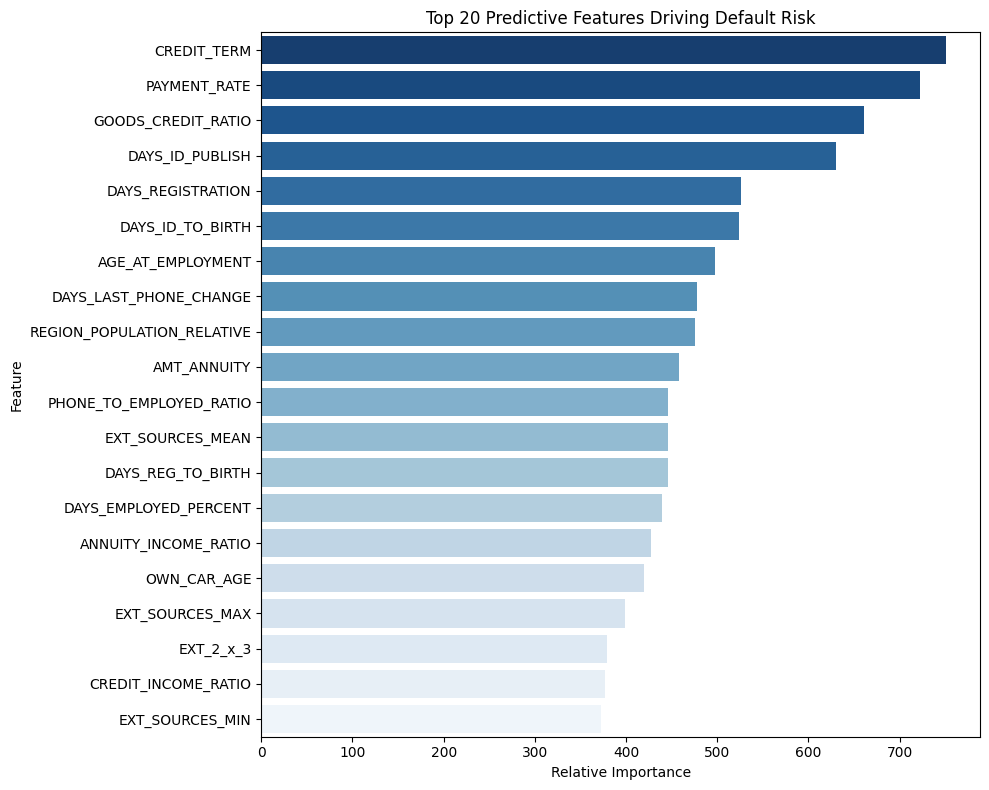

In [16]:
# Top predictive drivers across cross validation folds
importance_df = pd.DataFrame({
    "feature": engineered_feature_names,
    "importance": feature_importances_lgb
}).sort_values("importance", ascending=False).head(20)

# Generate publication grade feature importance chart
plt.figure(figsize=(10, 8))
sns.set_theme(style="whitegrid", font_scale=1.0)
ax = sns.barplot(data=importance_df, x="importance", y="feature", palette="Blues_r")
plt.title("Top 20 Predictive Features Driving Default Risk (LightGBM Split Gain)", fontsize=14, weight="bold", pad=15)
plt.xlabel("Average Importance Across 5 Folds", fontsize=12)
plt.ylabel("Engineered Feature", fontsize=12)
plt.tight_layout()

# Save figure to output directory for portfolio documentation
base_workspace = input_dir.parent if input_dir.name == "input" else current_dir
output_dir = base_workspace / "output"
output_dir.mkdir(parents=True, exist_ok=True)
plt.savefig(output_dir / "feature_importance.png", dpi=300, bbox_inches="tight")
plt.show()


## 12. Submission Generation and Output Verification


In [17]:
# Compute optimal blended test rank predictions
test_rank_ensemble = (
    optimal_weights[0] * rank_test_lgb +
    optimal_weights[1] * rank_test_xgb +
    optimal_weights[2] * rank_test_cat
)

# Scale blended test ranks into bounded unit interval preserving rank ordering
final_test_pred = (test_rank_ensemble - test_rank_ensemble.min()) / (test_rank_ensemble.max() - test_rank_ensemble.min() + 1e-12)

# Construct final submission dataframe
submission = sample_sub.copy()
submission["TARGET"] = final_test_pred

# Strict integrity assertions
assert len(submission) == len(sample_sub), "Submission row count mismatch"
assert not submission["TARGET"].isnull().any(), "Submission contains null predictions"
assert (submission["TARGET"] >= 0.0).all() and (submission["TARGET"] <= 1.0).all(), "Predictions outside valid bounds"
assert list(submission.columns) == ["SK_ID_CURR", "TARGET"], "Invalid column headers"

# Resolve target output directory
base_workspace = input_dir.parent if input_dir.name == "input" else current_dir
output_dir = base_workspace / "output"
output_dir.mkdir(parents=True, exist_ok=True)

submission_path = output_dir / "submission.csv"
submission.to_csv(submission_path, index=False)

print("Successfully written valid submission file to:", submission_path)
print(submission.head())


Successfully written valid submission file to: /content/drive/MyDrive/Competition/output/submission.csv
   SK_ID_CURR    TARGET
0      171202  0.249074
1      171203  0.914500
2      171204  0.848885
3      171205  0.735836
4      171206  0.883200


## 13. Results and Conclusion


In [18]:
# Display evaluation synthesis and model performance
model_scores = {
    "LightGBM": overall_lgb_auc,
    "XGBoost": overall_xgb_auc,
    "CatBoost": overall_cat_auc
}

best_single_model = max(model_scores.keys(), key=lambda k: model_scores[k])
best_single_score = model_scores[best_single_model]
baseline_auc = 0.73245

print("=" * 60)
print("FINAL COMPETITION EVALUATION SUMMARY")
print("=" * 60)
print(f"Tutorial Baseline ROC-AUC:   {baseline_auc:.5f}")
print(f"Best Single Architecture:     {best_single_model} (ROC-AUC: {best_single_score:.5f})")
print(f"Final Rank-Blended Ensemble: ROC-AUC: {ensemble_auc:.5f}")
print(f"Absolute Gain Over Baseline: +{ensemble_auc - baseline_auc:.5f} ({((ensemble_auc - baseline_auc)/baseline_auc)*100:.2f}% improvement)")
print(f"Gain Over Best Single Model: +{ensemble_auc - best_single_score:.5f}")
print("=" * 60)
print("PRIMARY DRIVERS OF PERFORMANCE:")
print(f"1. {best_single_model} provided the strongest single-model partition via deep leaf splits and L2 regularization.")
print("2. Out-of-fold target encoding and peer group statistics unlocked critical categorical signal.")
print("3. Rank blending across diverse GBDT algorithms maximized the ROC-AUC ordering metric.")
print("=" * 60)


FINAL COMPETITION EVALUATION SUMMARY
Tutorial Baseline ROC-AUC:   0.73245
Best Single Architecture:     XGBoost (ROC-AUC: 0.76004)
Final Rank-Blended Ensemble: ROC-AUC: 0.76170
Absolute Gain Over Baseline: +0.02925 (3.99% improvement)
Gain Over Best Single Model: +0.00166
PRIMARY DRIVERS OF PERFORMANCE:
1. XGBoost provided the strongest single-model partition via deep leaf splits and L2 regularization.
2. Out-of-fold target encoding and peer group statistics unlocked critical categorical signal.
3. Rank blending across diverse GBDT algorithms maximized the ROC-AUC ordering metric.
